In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz

N = 31  # Number of taps; filter order = 30
fs = 10000

def plot_filter(b, fs, name, cutoff):
    f, H = freqz(b, worN=4096, fs=fs)
    magnitude = 20 * np.log10(np.maximum(np.abs(H), 1e-10))
    plt.figure(figsize=(10, 3.5))
    plt.subplot(1, 2, 1)
    plt.stem(np.arange(N), b)
    plt.title(name + ' impulse response')
    plt.xlabel('Sample n')
    plt.ylabel('h[n]')
    plt.grid(True)
    plt.subplot(1, 2, 2)
    plt.plot(f / 1000, magnitude)
    for fc in np.atleast_1d(cutoff):
        plt.axvline(fc / 1000, color='red', linestyle='--')
    plt.title(f'{name}, fs = {fs / 1000:g} kHz')
    plt.xlabel('Frequency (kHz)')
    plt.ylabel('Magnitude (dB)')
    plt.xlim(0, fs / 2000)
    plt.ylim(-100, 5)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

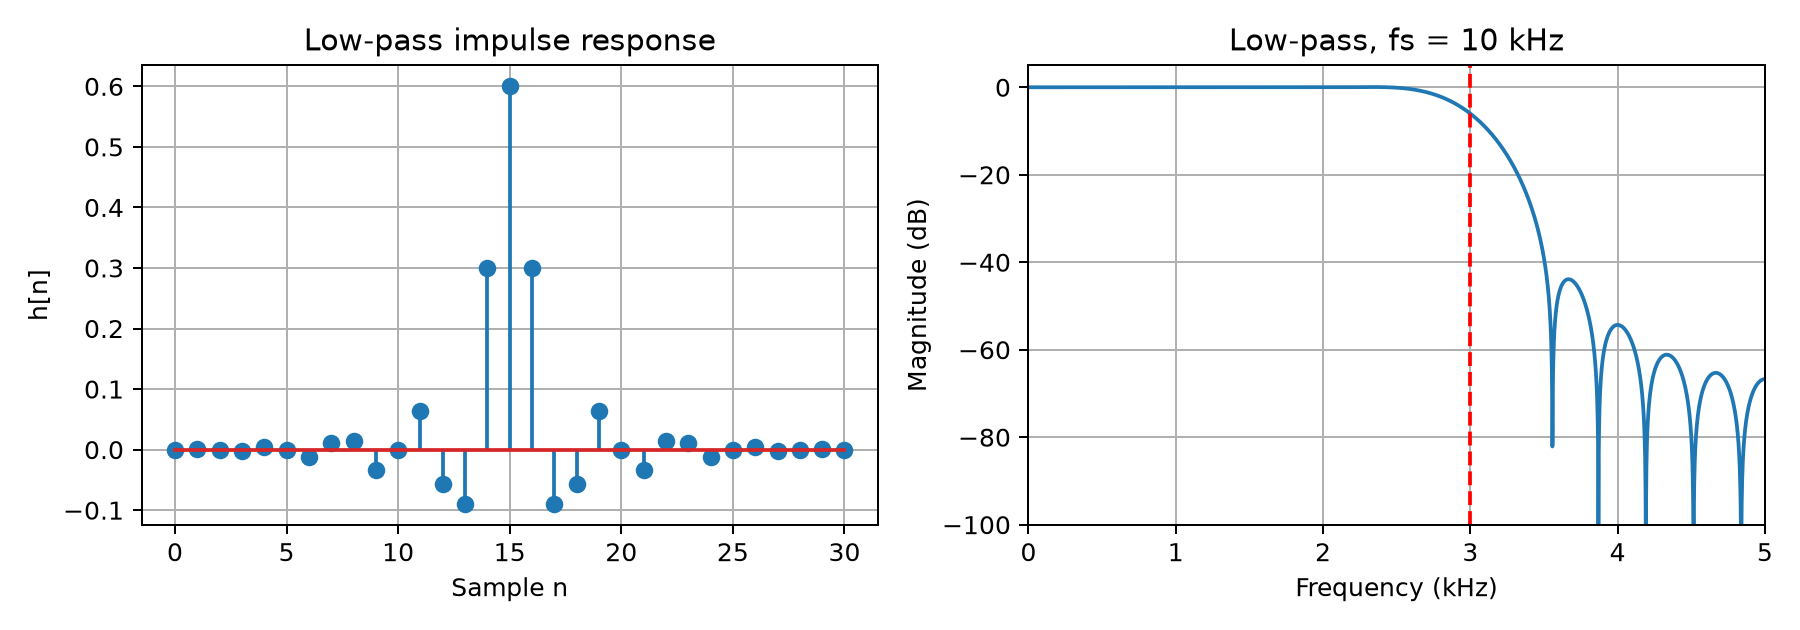

Low-pass coefficients: [ 0.00000e+00  2.36000e-04 -6.22000e-04 -1.48900e-03  4.55400e-03
 -0.00000e+00 -1.16230e-02  1.04730e-02  1.47630e-02 -3.30280e-02
  0.00000e+00  6.31700e-02 -5.64180e-02 -8.95170e-02  2.99462e-01
  6.00077e-01  2.99462e-01 -8.95170e-02 -5.64180e-02  6.31700e-02
  0.00000e+00 -3.30280e-02  1.47630e-02  1.04730e-02 -1.16230e-02
 -0.00000e+00  4.55400e-03 -1.48900e-03 -6.22000e-04  2.36000e-04
  0.00000e+00]


In [2]:
# 1. Low-pass: cutoff 3 kHz, sampling 10 kHz
low = firwin(N, 3000, window='hann', pass_zero='lowpass', fs=fs)
plot_filter(low, fs, 'Low-pass', 3000)
print('Low-pass coefficients:', np.round(low, 6))

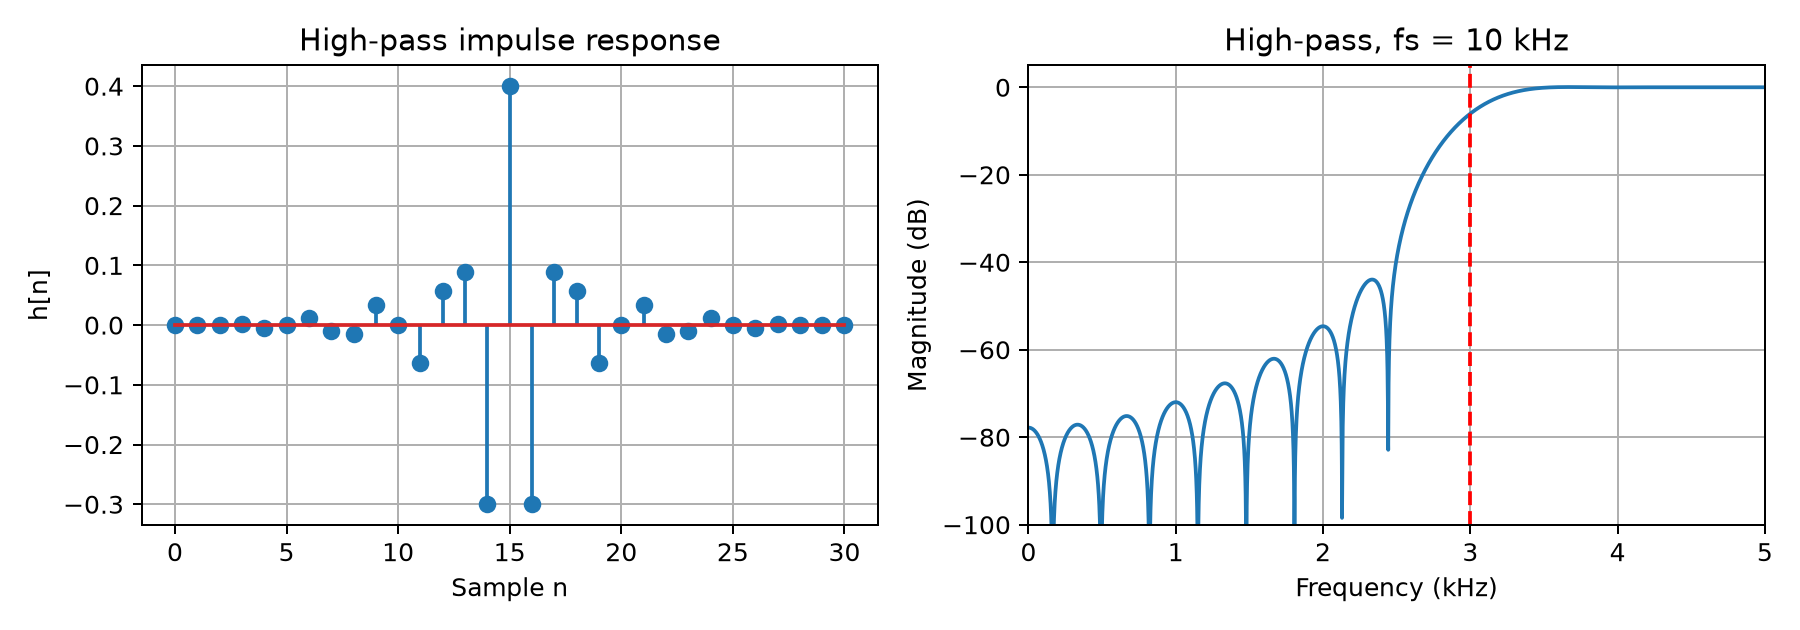

High-pass coefficients: [ 0.00000e+00 -2.36000e-04  6.22000e-04  1.48800e-03 -4.55100e-03
 -0.00000e+00  1.16160e-02 -1.04660e-02 -1.47540e-02  3.30080e-02
  0.00000e+00 -6.31330e-02  5.63850e-02  8.94640e-02 -2.99285e-01
  3.99816e-01 -2.99285e-01  8.94640e-02  5.63850e-02 -6.31330e-02
  0.00000e+00  3.30080e-02 -1.47540e-02 -1.04660e-02  1.16160e-02
 -0.00000e+00 -4.55100e-03  1.48800e-03  6.22000e-04 -2.36000e-04
  0.00000e+00]


In [3]:
# 2. High-pass: cutoff 3 kHz, sampling 10 kHz
high = firwin(N, 3000, window='hann', pass_zero='highpass', fs=fs)
plot_filter(high, fs, 'High-pass', 3000)
print('High-pass coefficients:', np.round(high, 6))

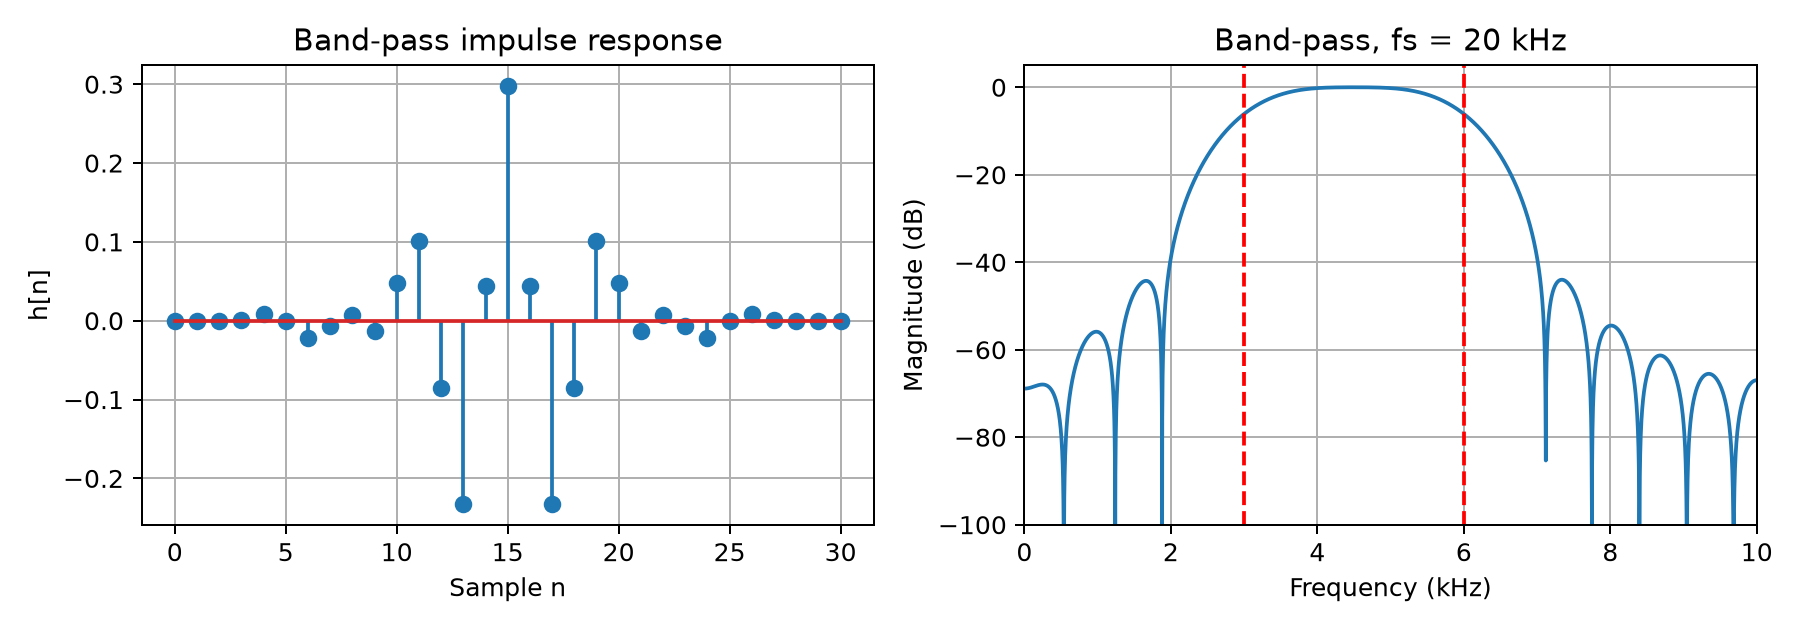

Band-pass coefficients: [-0.00000e+00  8.90000e-05 -2.92000e-04  9.12000e-04  8.35100e-03
 -0.00000e+00 -2.13150e-02 -6.41400e-03  6.93800e-03 -1.25020e-02
  4.73220e-02  1.01289e-01 -8.53020e-02 -2.32243e-01  4.43210e-02
  2.97331e-01  4.43210e-02 -2.32243e-01 -8.53020e-02  1.01289e-01
  4.73220e-02 -1.25020e-02  6.93800e-03 -6.41400e-03 -2.13150e-02
 -0.00000e+00  8.35100e-03  9.12000e-04 -2.92000e-04  8.90000e-05
 -0.00000e+00]


In [4]:
# 3. Band-pass: 3-6 kHz; corrected sampling rate 20 kHz
fs_band = 20000
band_pass = firwin(N, [3000, 6000], window='hann',
                    pass_zero='bandpass', fs=fs_band)
plot_filter(band_pass, fs_band, 'Band-pass', [3000, 6000])
print('Band-pass coefficients:', np.round(band_pass, 6))

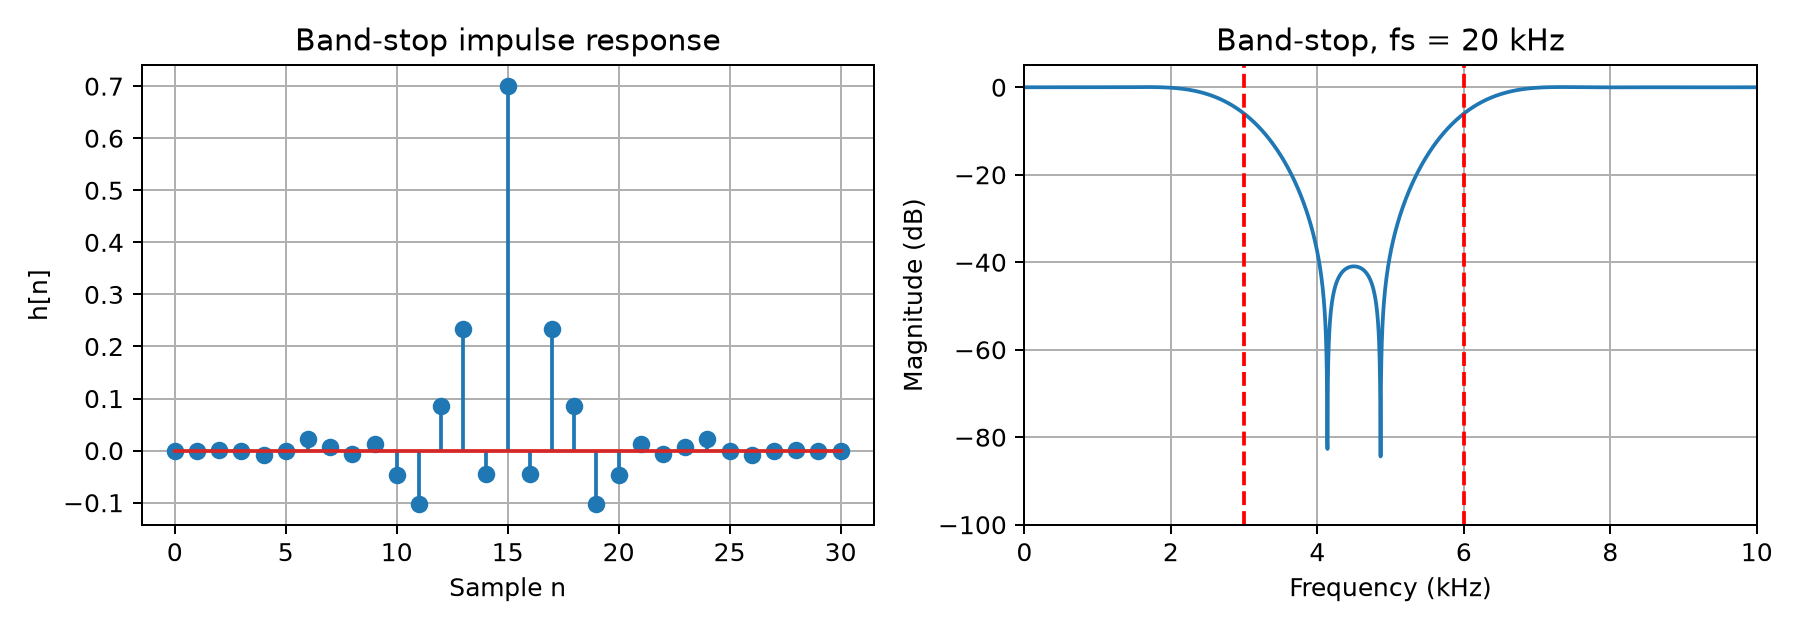

Band-stop coefficients: [ 0.00000e+00 -9.00000e-05  2.95000e-04 -9.20000e-04 -8.42300e-03
 -0.00000e+00  2.14990e-02  6.46900e-03 -6.99800e-03  1.26090e-02
 -4.77290e-02 -1.02161e-01  8.60360e-02  2.34242e-01 -4.47020e-02
  6.99746e-01 -4.47020e-02  2.34242e-01  8.60360e-02 -1.02161e-01
 -4.77290e-02  1.26090e-02 -6.99800e-03  6.46900e-03  2.14990e-02
 -0.00000e+00 -8.42300e-03 -9.20000e-04  2.95000e-04 -9.00000e-05
  0.00000e+00]


In [5]:
# 4. Band-stop: 3-6 kHz, sampling 20 kHz
band_stop = firwin(N, [3000, 6000], window='hann',
                    pass_zero='bandstop', fs=fs_band)
plot_filter(band_stop, fs_band, 'Band-stop', [3000, 6000])
print('Band-stop coefficients:', np.round(band_stop, 6))

**Conclusion:** All four FIR filters were designed using the Hann window. Low-pass passes frequencies below 3 kHz; high-pass passes frequencies above 3 kHz. Band-pass passes the 3-6 kHz band, while band-stop attenuates it. The finite filter length produces gradual transitions at the band edges. All coefficient sequences are symmetric, giving linear phase and a delay of 15 samples.

Reference: [SciPy firwin documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.firwin.html).